In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils')

neuron.load_mechanisms('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod')
h.load_file("stdrun.hoc")
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/conn'

In [2]:
def create_comps():
    basal = h.Section(name='basal')
    basal.L = 255
    basal.diam = 8.5
    basal.Ra = 100
    basal.cm = 1
    basal.insert('pas')
    
    soma = h.Section(name='soma')
    soma.L = soma.diam = 12
    soma.Ra = 100
    soma.cm = 1
    soma.insert('hh')

    stim = h.IClamp(soma(0.5))
    stim.delay = 20
    stim.dur = 2    
    stim.amp = 0.5

    return basal, soma, stim

In [3]:
def create_comps_basal_clamp_cad(bamp=2, bdur=25):
    basal = h.Section(name='basal')
    basal.L = 255
    basal.diam = 8.5
    basal.Ra = 100
    basal.cm = 1
    basal.insert('pas')
    basal.insert('cad_poirazi')

    vcb = h.VClamp(basal(0.5))
    vcb.dur[0] = 10
    vcb.amp[0] = -80
    vcb.dur[1] = bdur
    vcb.amp[1] = bamp   
    
    soma = h.Section(name='soma')
    soma.L = soma.diam = 12
    soma.Ra = 100
    soma.cm = 1
    soma.insert('hh')

    stim = h.IClamp(soma(0.5))
    stim.delay = 20
    stim.dur = 2    
    stim.amp = 0.5

    return basal, soma, stim, vcb

In [4]:
def create_comps_basal_clamp_ca_dyn_e2(bamp=2, bdur=25):
    basal = h.Section(name='basal')
    basal.L = 255
    basal.diam = 8.5
    basal.Ra = 100
    basal.cm = 1
    basal.insert('pas')
    
    basal.insert('CaDynamics_E2')
    for seg in basal: 
        seg.CaDynamics_E2.decay = 50
        seg.CaDynamics_E2.gamma = .0005096
    # basal.insert('Ca_HVA')
    # basal.insert('Ca_LVAst')
    vcb = h.VClamp(basal(0.5))
    vcb.dur[0] = 10
    vcb.amp[0] = -80
    vcb.dur[1] = bdur
    vcb.amp[1] = bamp   
    
    soma = h.Section(name='soma')
    soma.L = soma.diam = 12
    soma.Ra = 100
    soma.cm = 1
    soma.insert('hh')

    stim = h.IClamp(soma(0.5))
    stim.delay = 20
    stim.dur = 2    
    stim.amp = 0.5

    return basal, soma, stim, vcb

In [5]:
bamps = np.linspace(-80, 20, 20)


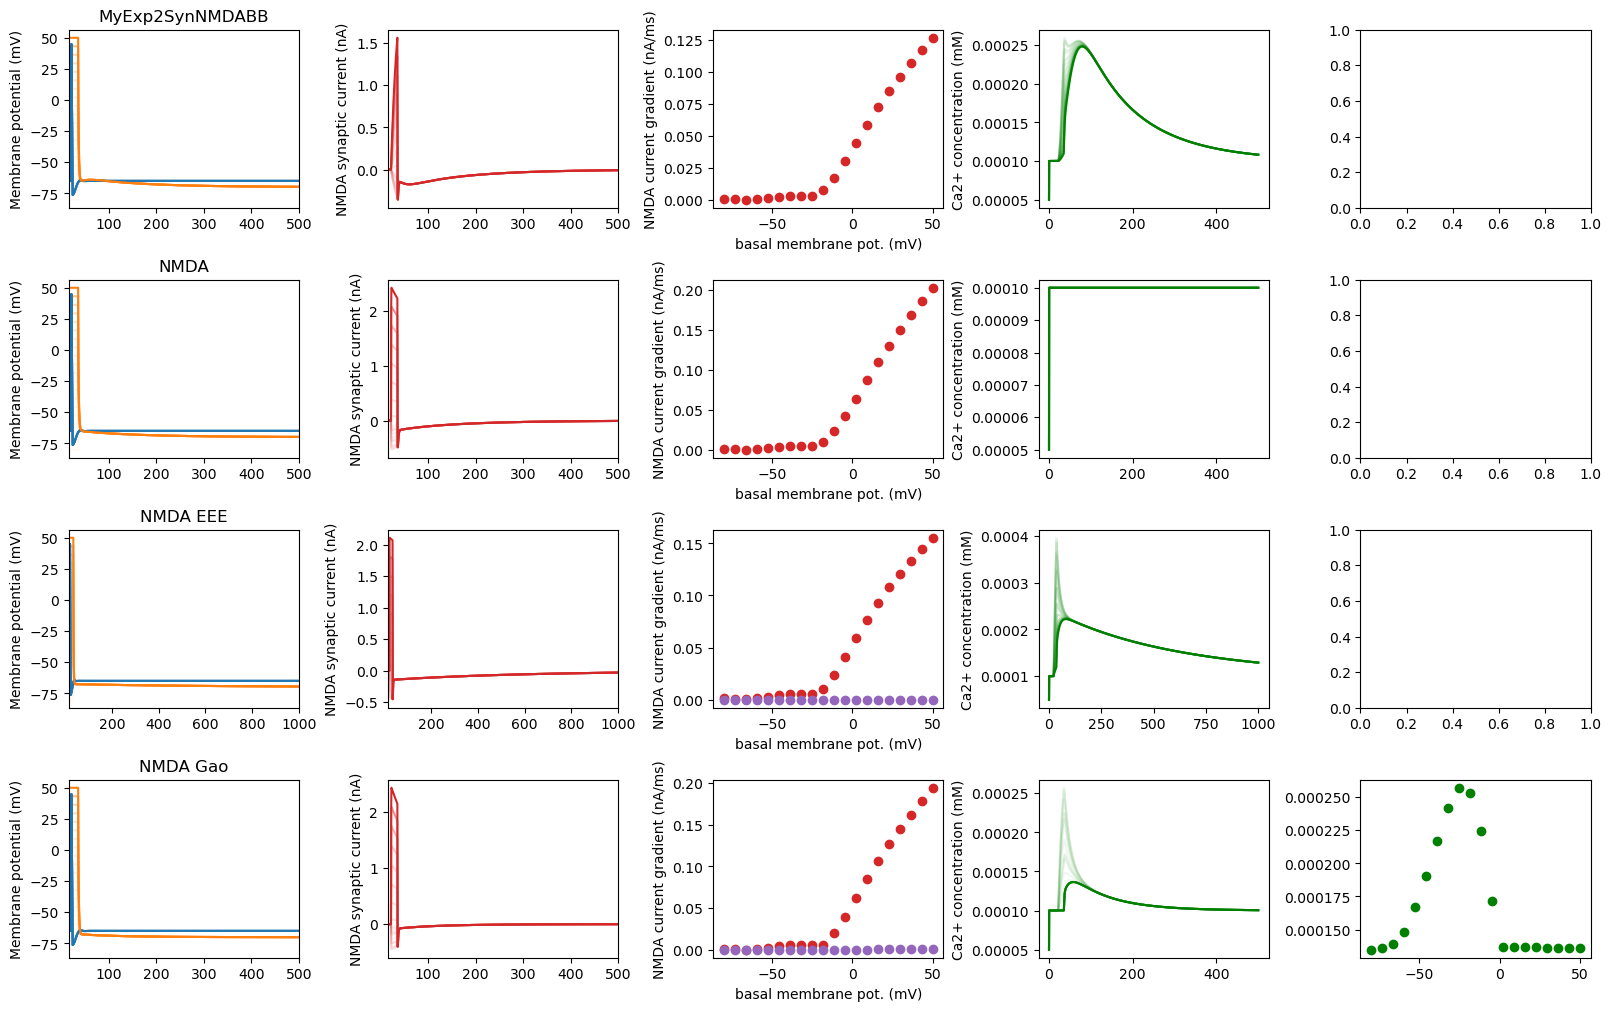

In [6]:
# this is with the synaptic weight in Neymotin 2011
fig, ax = plt.subplots(4,5, figsize=(16, 10), constrained_layout=True)
bamps = np.linspace(-80, 50, 20)
t1 = 11
t2 = 34
for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp_cad(bamp)
    syn = h.MyExp2SynNMDABB(basal(0.5))
    

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    ca_curr = h.Vector().record(basal(0.5)._ref_cai)
    

    h.finitialize(-65)
    h.continuerun(500)

    ax[0,0].set_title('MyExp2SynNMDABB')

    ax[0,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[0,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[0,0].set_ylabel('Membrane potential (mV)')
    ax[0,0].set_xlim(15, 500)

    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
    idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
    psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
    RMP = np.mean(v_basal.as_numpy()[idx:idx2])
    # ax[0,2].plot(RMP, psp, 'o', color='tab:orange')
    # ax[0,2].set_xlabel('basal membrane pot. (mV)')
    # ax[0,2].set_ylabel('PSP amplitude (mV)')
 
    ax[0,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[0,1].set_ylabel('NMDA synaptic current (nA)')
    ax[0,1].set_xlim(15, 500)

    idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
    ax[0,2].plot(RMP, nmda_grad, 'o', color='C3')
    ax[0,2].set_xlabel('basal membrane pot. (mV)')
    ax[0,2].set_ylabel('NMDA current gradient (nA/ms)')

    ax[0,3].plot(t, ca_curr, color='green', alpha=1/(len(bamps)-b))
    ax[0,3].set_ylabel('Ca2+ concentration (mM)')

for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp_cad(bamp)
    syn = h.NMDA(basal(0.5))
    

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    ca_curr = h.Vector().record(basal(0.5)._ref_cai)
    

    h.finitialize(-65)
    h.continuerun(500)

    ax[1,0].set_title('NMDA')

    ax[1,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[1,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[1,0].set_ylabel('Membrane potential (mV)')
    ax[1,0].set_xlim(15, 500)

    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
    idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
    psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
    RMP = np.mean(v_basal.as_numpy()[idx:idx2])
    # ax[1,2].plot(RMP, psp, 'o', color='tab:orange')
    # ax[1,2].set_xlabel('basal membrane pot. (mV)')
    # ax[1,2].set_ylabel('PSP amplitude (mV)')
 
    ax[1,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[1,1].set_ylabel('NMDA synaptic current (nA)')
    ax[1,1].set_xlim(15, 500)

    idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
    ax[1,2].plot(RMP, nmda_grad, 'o', color='C3')
    ax[1,2].set_xlabel('basal membrane pot. (mV)')
    ax[1,2].set_ylabel('NMDA current gradient (nA/ms)')

    ax[1,3].plot(t, ca_curr, color='green', alpha=1/(len(bamps)-b))
    ax[1,3].set_ylabel('Ca2+ concentration (mM)')

for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp_cad(bamp)
    syn = h.NMDAeee(basal(0.5))
    

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    ca_curr = h.Vector().record(basal(0.5)._ref_ica)
    ca_con = h.Vector().record(basal(0.5)._ref_cai)
    

    h.finitialize(-65)
    h.continuerun(1000)

    ax[2,0].set_title('NMDA EEE')

    ax[2,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[2,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[2,0].set_ylabel('Membrane potential (mV)')
    ax[2,0].set_xlim(15, 1000)

    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
    idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
    psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
    RMP = np.mean(v_basal.as_numpy()[idx:idx2])
    # ax[1,2].plot(RMP, psp, 'o', color='tab:orange')
    # ax[1,2].set_xlabel('basal membrane pot. (mV)')
    # ax[1,2].set_ylabel('PSP amplitude (mV)')
 
    ax[2,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
   
    ax[2,1].set_ylabel('NMDA synaptic current (nA)')
    ax[2,1].set_xlim(15, 1000)

    idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
    ax[2,2].plot(RMP, nmda_grad, 'o', color='C3')
    ca_grad = np.max(np.abs(np.gradient(ca_curr.as_numpy()[idx:])))
    ax[2,2].plot(RMP, ca_grad, 'o', color='C4')
    ax[2,2].set_xlabel('basal membrane pot. (mV)')
    ax[2,2].set_ylabel('NMDA current gradient (nA/ms)')

    ax[2,3].plot(t, ca_con, color='green', alpha=1/(len(bamps)-b))
    ax[2,3].set_ylabel('Ca2+ concentration (mM)')

for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp_cad(bamp)
    syn = h.NMDA_gao(basal(0.5))
    

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    ca_curr = h.Vector().record(basal(0.5)._ref_ica)
    ca_con = h.Vector().record(basal(0.5)._ref_cai)
    

    h.finitialize(-65)
    h.continuerun(500)

    ax[3,0].set_title('NMDA Gao')

    ax[3,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[3,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[3,0].set_ylabel('Membrane potential (mV)')
    ax[3,0].set_xlim(15, 500)

    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
    idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
    psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
    RMP = np.mean(v_basal.as_numpy()[idx:idx2])
    # ax[1,2].plot(RMP, psp, 'o', color='tab:orange')
    # ax[1,2].set_xlabel('basal membrane pot. (mV)')
    # ax[1,2].set_ylabel('PSP amplitude (mV)')
 
    ax[3,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
   
    ax[3,1].set_ylabel('NMDA synaptic current (nA)')
    ax[3,1].set_xlim(15, 500)

    idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
    ax[3,2].plot(RMP, nmda_grad, 'o', color='C3')
    ca_grad = np.max(np.abs(np.gradient(ca_curr.as_numpy()[idx:])))
    ax[3,2].plot(RMP, ca_grad, 'o', color='C4')
    ax[3,2].set_xlabel('basal membrane pot. (mV)')
    ax[3,2].set_ylabel('NMDA current gradient (nA/ms)')

    ax[3,3].plot(t, ca_con, color='green', alpha=1/(len(bamps)-b))
    ax[3,3].set_ylabel('Ca2+ concentration (mM)')
    #ax[3,3].vlines(35, 0, 5e-5, color='gray', linestyle='--', alpha=0.5)

    ax[3,4].plot(RMP, np.max(ca_con.as_numpy()), 'o', color='green')

fig.savefig(f'{pathfig}/NMDA_comparison_depolarization_Neymotin_weight.png')


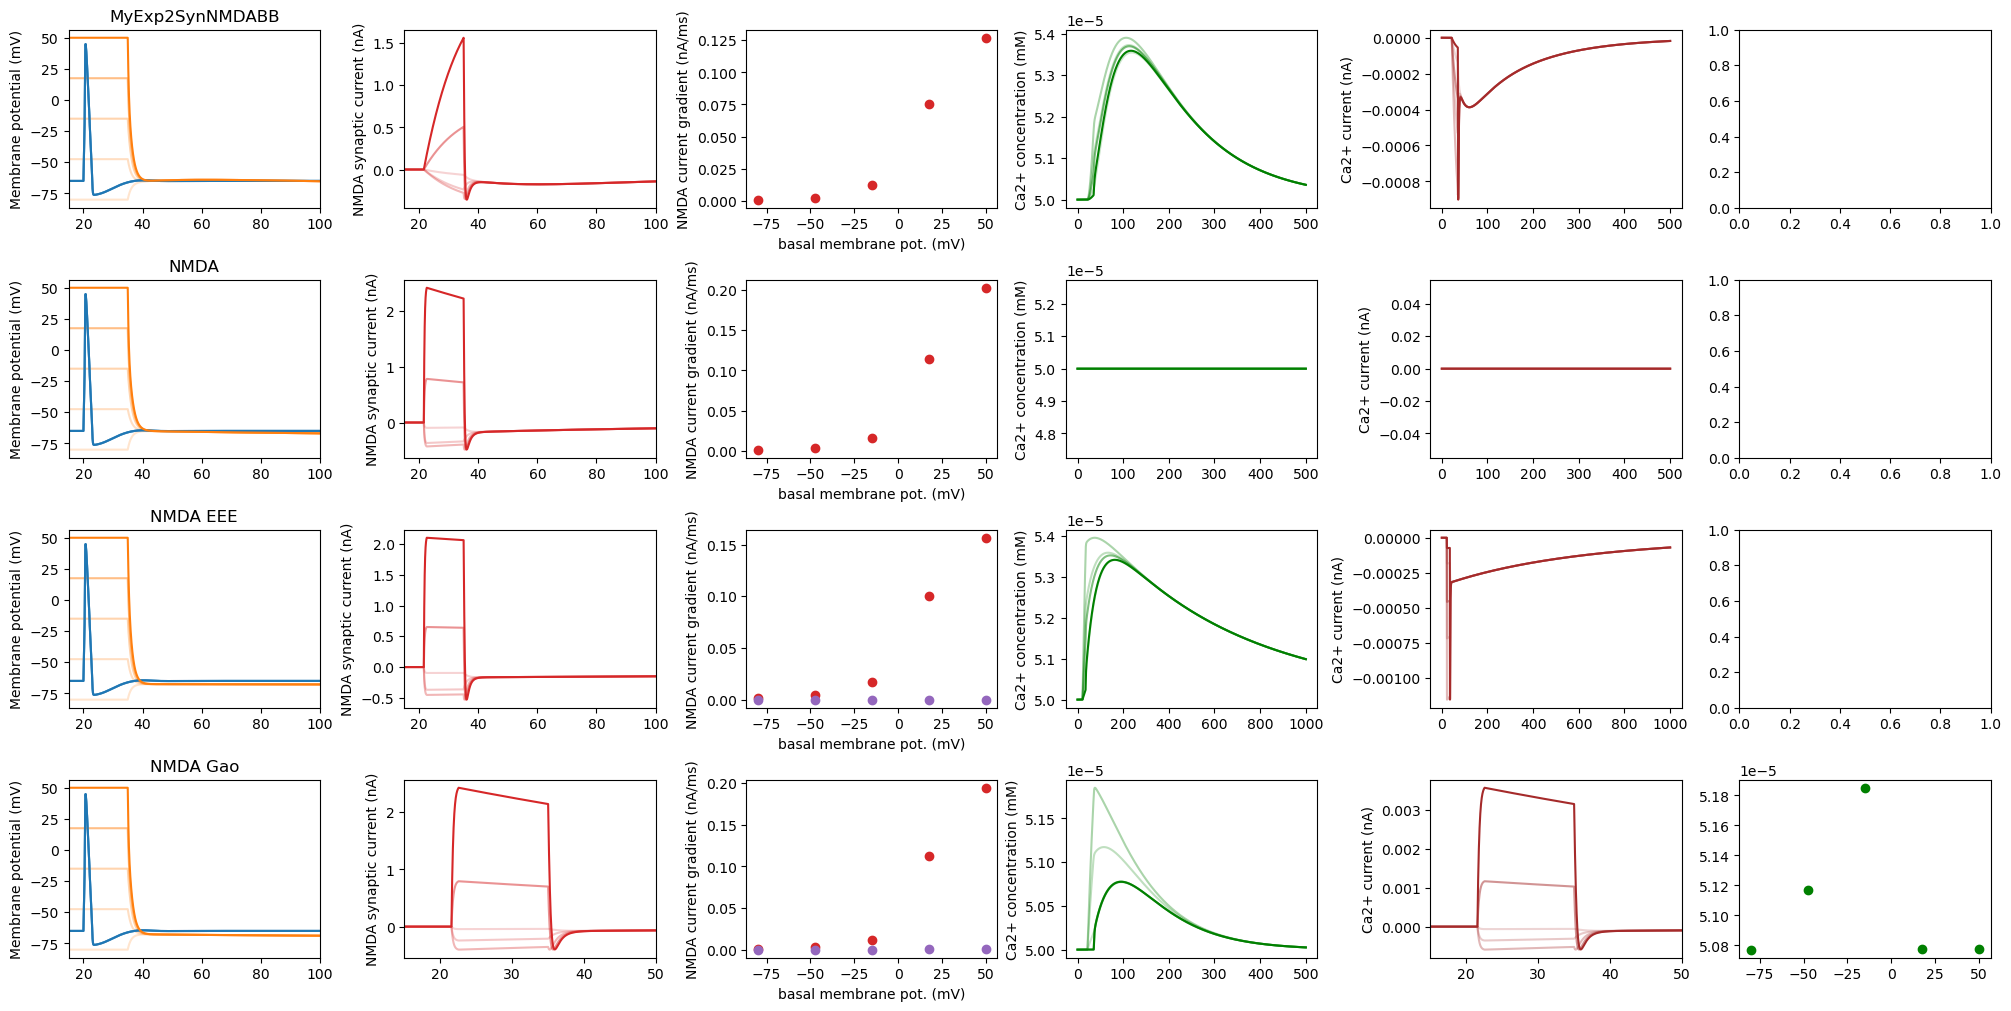

In [7]:
# this is with the synaptic weight in Neymotin 2011
fig, ax = plt.subplots(4,6, figsize=(20, 10), constrained_layout=True)
bamps = np.linspace(-80, 50, 5)
t1 = 11
t2 = 34
for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp_ca_dyn_e2(bamp)
    syn = h.MyExp2SynNMDABB(basal(0.5))
    

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    ca_con = h.Vector().record(basal(0.5)._ref_cai)
    ca_curr = h.Vector().record(basal(0.5)._ref_ica)
    

    h.finitialize(-65)
    h.continuerun(500)

    ax[0,0].set_title('MyExp2SynNMDABB')

    ax[0,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[0,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[0,0].set_ylabel('Membrane potential (mV)')
    ax[0,0].set_xlim(15, 100)

    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
    idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
    psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
    RMP = np.mean(v_basal.as_numpy()[idx:idx2])
    # ax[0,2].plot(RMP, psp, 'o', color='tab:orange')
    # ax[0,2].set_xlabel('basal membrane pot. (mV)')
    # ax[0,2].set_ylabel('PSP amplitude (mV)')
 
    ax[0,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[0,1].set_ylabel('NMDA synaptic current (nA)')
    ax[0,1].set_xlim(15, 100)

    idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
    ax[0,2].plot(RMP, nmda_grad, 'o', color='C3')
    ax[0,2].set_xlabel('basal membrane pot. (mV)')
    ax[0,2].set_ylabel('NMDA current gradient (nA/ms)')

    ax[0,3].plot(t, ca_con, color='green', alpha=1/(len(bamps)-b))
    ax[0,3].set_ylabel('Ca2+ concentration (mM)')

    ax[0,4].plot(t, ca_curr, color='brown', alpha=1/(len(bamps)-b))
    ax[0,4].set_ylabel('Ca2+ current (nA)')

for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp_ca_dyn_e2(bamp)
    syn = h.NMDA(basal(0.5))
    

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    ca_con = h.Vector().record(basal(0.5)._ref_cai)
    ca_curr = h.Vector().record(basal(0.5)._ref_ica)
    

    h.finitialize(-65)
    h.continuerun(500)

    ax[1,0].set_title('NMDA')

    ax[1,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[1,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[1,0].set_ylabel('Membrane potential (mV)')
    ax[1,0].set_xlim(15, 100)

    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
    idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
    psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
    RMP = np.mean(v_basal.as_numpy()[idx:idx2])
    # ax[1,2].plot(RMP, psp, 'o', color='tab:orange')
    # ax[1,2].set_xlabel('basal membrane pot. (mV)')
    # ax[1,2].set_ylabel('PSP amplitude (mV)')
 
    ax[1,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[1,1].set_ylabel('NMDA synaptic current (nA)')
    ax[1,1].set_xlim(15, 100)

    idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
    ax[1,2].plot(RMP, nmda_grad, 'o', color='C3')
    ax[1,2].set_xlabel('basal membrane pot. (mV)')
    ax[1,2].set_ylabel('NMDA current gradient (nA/ms)')

    ax[1,3].plot(t, ca_con, color='green', alpha=1/(len(bamps)-b))
    ax[1,3].set_ylabel('Ca2+ concentration (mM)')

    ax[1,4].plot(t, ca_curr, color='brown', alpha=1/(len(bamps)-b))
    ax[1,4].set_ylabel('Ca2+ current (nA)')

for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp_ca_dyn_e2(bamp)
    syn = h.NMDAeee(basal(0.5))
    

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    ca_curr = h.Vector().record(basal(0.5)._ref_ica)
    ca_con = h.Vector().record(basal(0.5)._ref_cai)
    

    h.finitialize(-65)
    h.continuerun(1000)

    ax[2,0].set_title('NMDA EEE')

    ax[2,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[2,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[2,0].set_ylabel('Membrane potential (mV)')
    ax[2,0].set_xlim(15, 100)

    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
    idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
    psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
    RMP = np.mean(v_basal.as_numpy()[idx:idx2])
    # ax[1,2].plot(RMP, psp, 'o', color='tab:orange')
    # ax[1,2].set_xlabel('basal membrane pot. (mV)')
    # ax[1,2].set_ylabel('PSP amplitude (mV)')
 
    ax[2,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
   
    ax[2,1].set_ylabel('NMDA synaptic current (nA)')
    ax[2,1].set_xlim(15, 100)

    idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
    ax[2,2].plot(RMP, nmda_grad, 'o', color='C3')
    ca_grad = np.max(np.abs(np.gradient(ca_curr.as_numpy()[idx:])))
    ax[2,2].plot(RMP, ca_grad, 'o', color='C4')
    ax[2,2].set_xlabel('basal membrane pot. (mV)')
    ax[2,2].set_ylabel('NMDA current gradient (nA/ms)')

    ax[2,3].plot(t, ca_con, color='green', alpha=1/(len(bamps)-b))
    ax[2,3].set_ylabel('Ca2+ concentration (mM)')

    ax[2,4].plot(t, ca_curr, color='brown', alpha=1/(len(bamps)-b))
    ax[2,4].set_ylabel('Ca2+ current (nA)')

for b,bamp in enumerate(bamps):
   # h('forall delete_section()')
    # del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp_ca_dyn_e2(bamp)
    syn = h.NMDA_gao(basal(0.5))
    

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    ca_curr = h.Vector().record(basal(0.5)._ref_ica)
    ca_con = h.Vector().record(basal(0.5)._ref_cai)
    

    h.finitialize(-65)
    h.continuerun(500)

    ax[3,0].set_title('NMDA Gao')

    ax[3,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[3,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[3,0].set_ylabel('Membrane potential (mV)')
    ax[3,0].set_xlim(15, 100)

    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
    idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
    psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
    RMP = np.mean(v_basal.as_numpy()[idx:idx2])
    # ax[1,2].plot(RMP, psp, 'o', color='tab:orange')
    # ax[1,2].set_xlabel('basal membrane pot. (mV)')
    # ax[1,2].set_ylabel('PSP amplitude (mV)')
 
    ax[3,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
   
    ax[3,1].set_ylabel('NMDA synaptic current (nA)')
    ax[3,1].set_xlim(15, 50)

    idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
    ax[3,2].plot(RMP, nmda_grad, 'o', color='C3')
    ca_grad = np.max(np.abs(np.gradient(ca_curr.as_numpy()[idx:])))
    ax[3,2].plot(RMP, ca_grad, 'o', color='C4')
    ax[3,2].set_xlabel('basal membrane pot. (mV)')
    ax[3,2].set_ylabel('NMDA current gradient (nA/ms)')

    ax[3,3].plot(t, ca_con, color='green', alpha=1/(len(bamps)-b))
    ax[3,3].set_ylabel('Ca2+ concentration (mM)')

    ax[3,4].plot(t, ca_curr, color='brown', alpha=1/(len(bamps)-b))
    ax[3,4].set_ylabel('Ca2+ current (nA)')
    ax[3,4].set_xlim(15, 50)

    ax[3,5].plot(RMP, np.max(ca_con.as_numpy()), 'o', color='green')

    #ax[3,3].vlines(35, 0, 5e-5, color='gray', linestyle='--', alpha=0.5)
#fig.savefig(f'{pathfig}/NMDA_comparison_depolarization_Neymotin_weight.png')

In [8]:
# Investigate different Ca dynamics
def CaDynamics_E2(ica, cai):
    minCai = 5e-5
    decay = 122
    gamma = 0.0005096
    depth = 0.1
    cai_strich = -(10000)*(ica*gamma/(2*h.FARADAY*depth)) - (cai - minCai)/decay

    return cai+cai_strich

def cad(ica, cai):

    
    depth = 0.1
    taur = 100
    #cainf = 100e-6
    cainf = 5e-5
    gamma = 0.0005096
    drive_channel =  - (10000) * ica / (2 * h.FARADAY * depth)
     
    ca_strich = drive_channel/18 + (cainf - cai)/taur*7   
    return cai + ca_strich

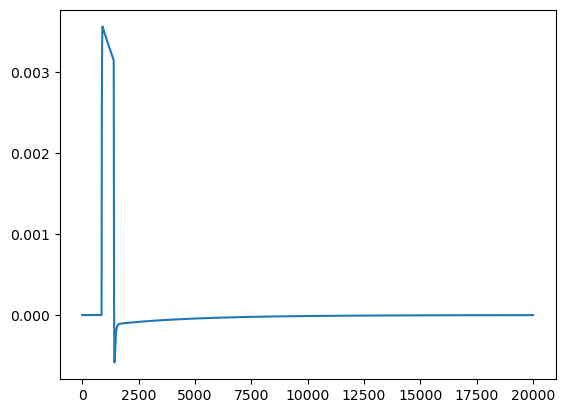

In [9]:
plt.plot(ca_curr)

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_54892/2058448672.py:65: RuntimeWarning: invalid value encountered in divide
  ax3tw.plot(t, np.abs(nmda_curr_e2 - nmda_curr_cad)/nmda_curr_cad*100, color='gray', linestyle=':')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_54892/2058448672.py:71: RuntimeWarning: invalid value encountered in divide
  ax5tw.plot(t, np.abs(ca_curr_e2 - ca_curr_cad)/ca_curr_cad *100, color='gray', linestyle=':')


Text(0, 0.5, 'Difference (%)')

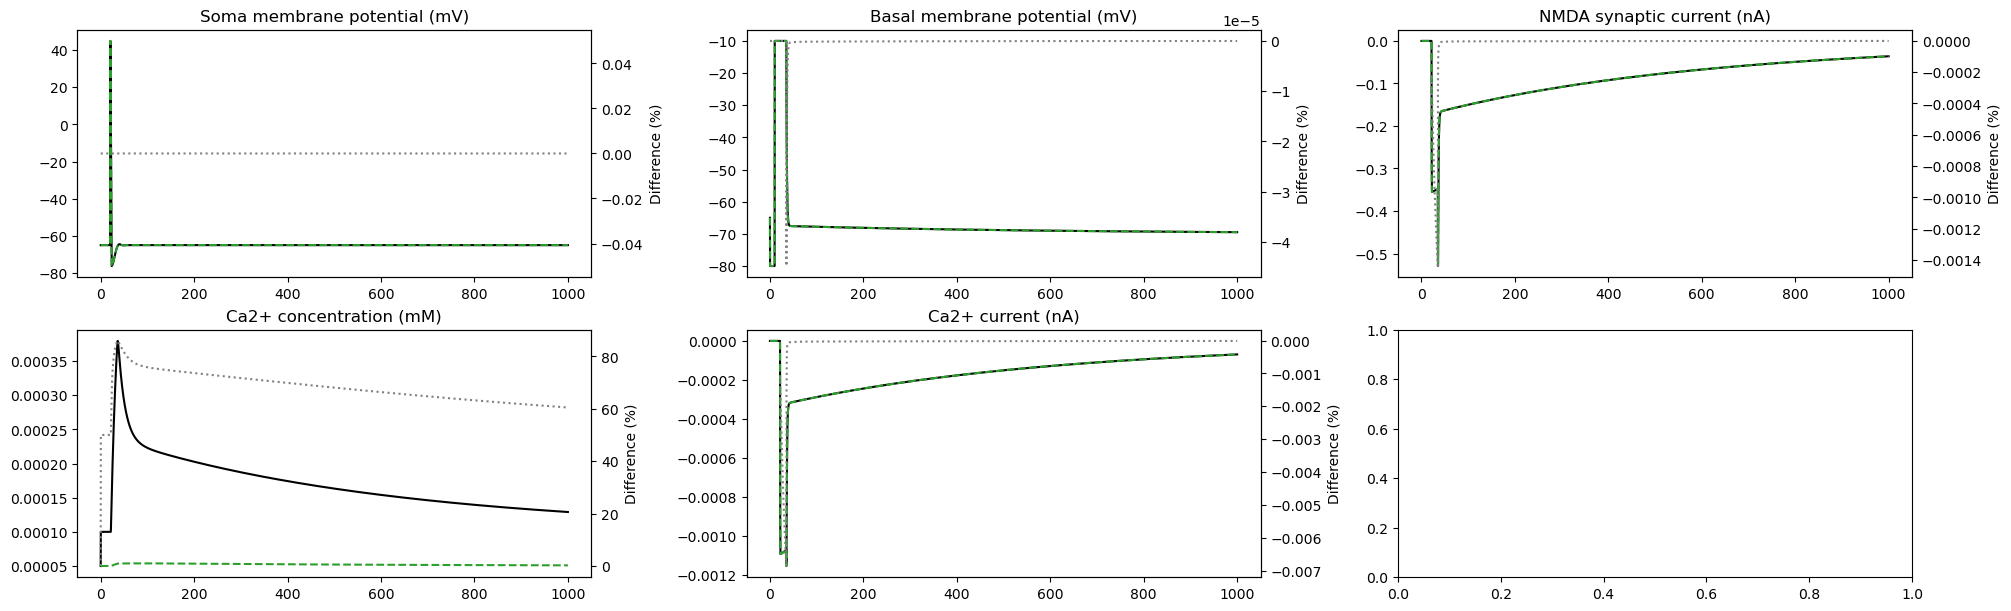

In [10]:
fig, ax = plt.subplots(2,3, figsize=(20, 6), constrained_layout=True)
ax = ax.flatten()
bamp = -10

basal, soma, stim, stimb = create_comps_basal_clamp_cad(bamp)
syn = h.NMDAeee(basal(0.5))
nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
nc.weight[0] = 0.05
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_soma_cad = h.Vector().record(soma(0.5)._ref_v)
v_basal_cad = h.Vector().record(basal(0.5)._ref_v)
nmda_curr_cad = h.Vector().record(syn._ref_i)
ca_curr_cad = h.Vector().record(basal(0.5)._ref_ica)
ca_con_cad = h.Vector().record(basal(0.5)._ref_cai)

h.finitialize(-65)
h.continuerun(1000)
ax[0].plot(t, v_soma_cad, color='k')
ax[0].set_title('Soma membrane potential (mV)')

ax[1].plot(t, v_basal_cad, color='k')
ax[1].set_title('Basal membrane potential (mV)')

ax[2].plot(t, nmda_curr_cad, color='k')
ax[2].set_title('NMDA synaptic current (nA)')

ax[3].plot(t, ca_con_cad, color='k')
ax[3].set_title('Ca2+ concentration (mM)')  

ax[4].plot(t, ca_curr_cad, color='k')
ax[4].set_title('Ca2+ current (nA)')

basal, soma, stim, stimb = create_comps_basal_clamp_ca_dyn_e2(bamp)
syn = h.NMDAeee(basal(0.5))
nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
nc.weight[0] = 0.05
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_soma_e2 = h.Vector().record(soma(0.5)._ref_v)
v_basal_e2 = h.Vector().record(basal(0.5)._ref_v)
nmda_curr_e2 = h.Vector().record(syn._ref_i)
ca_curr_e2 = h.Vector().record(basal(0.5)._ref_ica)
ca_con_e2 = h.Vector().record(basal(0.5)._ref_cai)


h.finitialize(-65)
h.continuerun(1000)

ax[0].plot(t, v_soma_e2, color='C2', linestyle='--')
ax[1].plot(t, v_basal_e2, color='C2', linestyle='--')
ax[2].plot(t, nmda_curr_e2, color='C2', linestyle='--')
ax[3].plot(t, ca_con_e2, color='C2', linestyle='--')
ax[4].plot(t, ca_curr_e2, color='C2', linestyle='--')

ax1tw = ax[0].twinx()
ax1tw.plot(t, np.abs(v_soma_e2 - v_soma_cad)/v_soma_cad*100, color='gray', linestyle=':')
ax1tw.set_ylabel('Difference (%)')
ax2tw = ax[1].twinx()
ax2tw.plot(t, np.abs(v_basal_e2 - v_basal_cad)/v_basal_cad*100, color='gray', linestyle=':')
ax2tw.set_ylabel('Difference (%)')
ax3tw = ax[2].twinx()
ax3tw.plot(t, np.abs(nmda_curr_e2 - nmda_curr_cad)/nmda_curr_cad*100, color='gray', linestyle=':')
ax3tw.set_ylabel('Difference (%)')
ax4tw = ax[3].twinx()   
ax4tw.plot(t, np.abs(ca_con_e2 - ca_con_cad.as_numpy())/ca_con_cad*100, color='gray', linestyle=':')
ax4tw.set_ylabel('Difference (%)')
ax5tw = ax[4].twinx()   
ax5tw.plot(t, np.abs(ca_curr_e2 - ca_curr_cad)/ca_curr_cad *100, color='gray', linestyle=':')
ax5tw.set_ylabel('Difference (%)')

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_54892/1735535615.py:47: RuntimeWarning: invalid value encountered in divide
  ax5tw.plot(t, np.abs((ca_curr_e2 - ca_curr_cad.as_numpy())/ca_curr_cad.as_numpy()) *100, color='gray', linestyle=':')


Text(0, 0.5, 'Difference (%)')

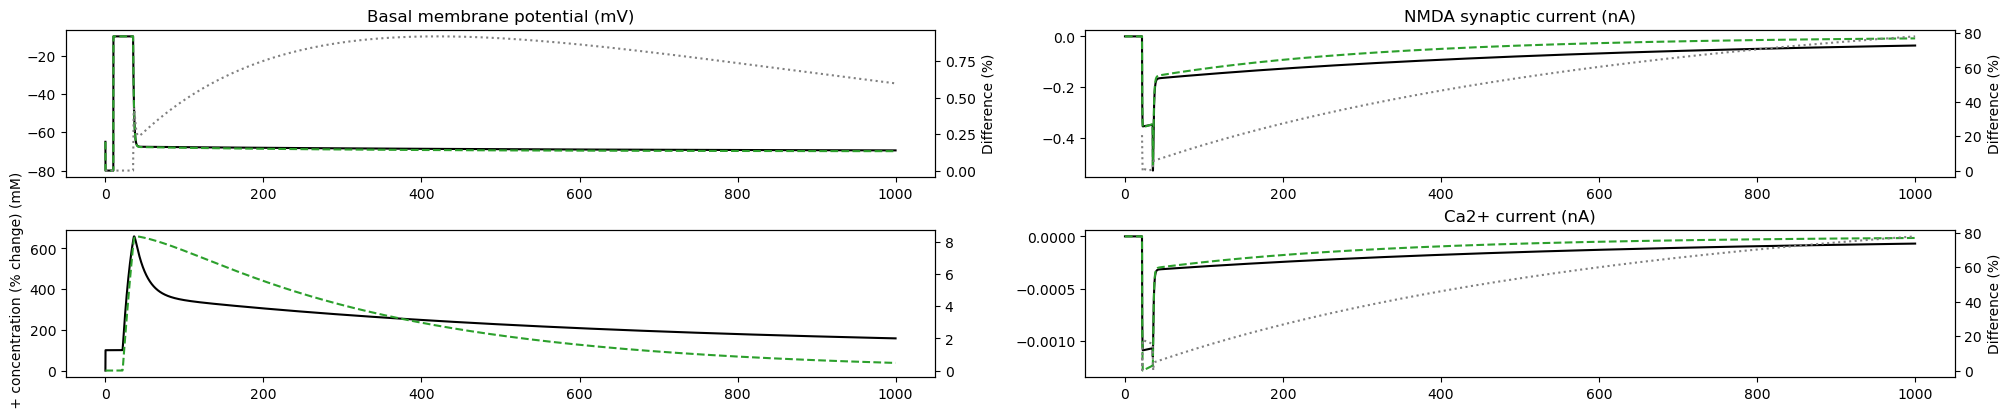

In [11]:
# Gordon, Polsky, Schiller 2006: Calcium goes down to baseline within 450 ms
# adjust NMDA accordingly
basal, soma, stim, stimb = create_comps_basal_clamp_ca_dyn_e2(bamp)
syn = h.NMDAeee_KD(basal(0.5))
nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
nc.weight[0] = 0.05
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_soma_e2 = h.Vector().record(soma(0.5)._ref_v)
v_basal_e2 = h.Vector().record(basal(0.5)._ref_v)
nmda_curr_e2 = h.Vector().record(syn._ref_i)
ca_curr_e2 = h.Vector().record(basal(0.5)._ref_ica)
ca_con_e2 = h.Vector().record(basal(0.5)._ref_cai)


h.finitialize(-65)
h.continuerun(1000)
fig, ax = plt.subplots(2,2, figsize=(20, 4), constrained_layout=True)
ax = ax.flatten()

ax[0].plot(t, v_basal_cad, color='k')
ax[0].set_title('Basal membrane potential (mV)')

ax[1].plot(t, nmda_curr_cad, color='k')
ax[1].set_title('NMDA synaptic current (nA)')

ax[2].plot(t, np.abs(ca_con_cad-5.e-5)/5.e-5*100, color='k')
ax[2].set_ylabel('Ca2+ concentration (% change) (mM)')  

ax[3].plot(t, ca_curr_cad, color='k')
ax[3].set_title('Ca2+ current (nA)')
ax[0].plot(t, v_basal_e2, color='C2', linestyle='--')
ax[1].plot(t, nmda_curr_e2, color='C2', linestyle='--')
ax[3].plot(t, ca_curr_e2, color='C2', linestyle='--')

ax2tw = ax[0].twinx()
ax2tw.plot(t, np.abs((v_basal_e2 - v_basal_cad)/v_basal_cad)*100, color='gray', linestyle=':')
ax2tw.set_ylabel('Difference (%)')
ax3tw = ax[1].twinx()
ax3tw.plot(t, np.abs((nmda_curr_e2 - nmda_curr_cad)/nmda_curr_cad)*100, color='gray', linestyle=':')
ax3tw.set_ylabel('Difference (%)')
ax4tw = ax[2].twinx()   
ax4tw.plot(t, np.abs(ca_con_e2-5.e-5)/5.e-5*100, color='C2', linestyle='--')

ax5tw = ax[3].twinx()   
ax5tw.plot(t, np.abs((ca_curr_e2 - ca_curr_cad.as_numpy())/ca_curr_cad.as_numpy()) *100, color='gray', linestyle=':')
ax5tw.set_ylabel('Difference (%)')

ValueError: x and y must have same first dimension, but have shapes (40001,) and (20001,)

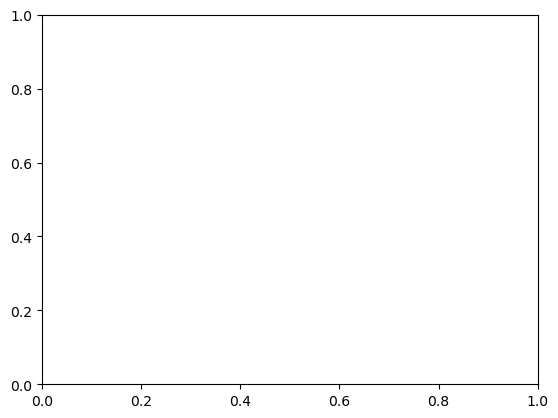

In [12]:
#ca_curr = ca_curr.as_numpy()

cai_e2 = np.zeros(len(ca_curr)+1)
cai_cad = np.zeros(len(ca_curr)+1)
cai_e2[0] = 5e-5
cai_cad[0] = 5e-5
for i,ica in enumerate(ca_curr):
    cai_e2[i+1] = CaDynamics_E2(ica, cai_e2[i])
    cai_cad[i+1] = cad(ica, cai_cad[i])

plt.plot(t, cai_e2[1:], label='CaDynamics_E2')
plt.plot(t, cai_cad[1:], label='cad')
plt.xlabel('Time (ms)')
plt.legend()

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_11171/1652852497.py:6: RuntimeWarning: divide by zero encountered in scalar divide
  f = R*(celsius+273.15)/(z*(1e-3)*h.FARADAY)


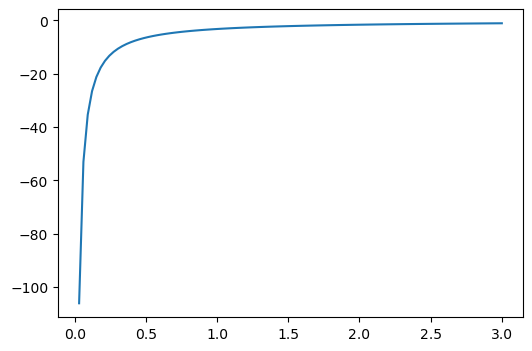

In [ ]:
celsius = 37.0
R = 1
cai = 5e-5
cao = 2
def ghkg(v, cai, cao, z):
    f = R*(celsius+273.15)/(z*(1e-3)*h.FARADAY)
    xi = v/f
    exi = np.exp(xi)
    if np.abs(xi) < 1e-4:
        fxi = 1 - xi/2
    else:
        fxi = xi/(exi - 1)
    ghkg = f*((cai/cao)*exi - 1)*fxi

    return ghkg

z = np.linspace(0, 3, 100)

v = 0

ghkg_values = np.ones_like(z)
for i,iz in enumerate(z):
    ghkg_values[i] = ghkg(v, cai, cao, iz)
plt.figure(figsize=(6,4))
plt.plot(z, ghkg_values)

In [ ]:
# fig, ax = plt.subplots(2, 4, figsize=(20, 5), sharex=True, constrained_layout=True)

# basal, soma, stim = create_comps()
# syn = h.Exp2Syn(basal(0.5))
# syn.tau1 = 1
# syn.tau2 = 10
# syn.e = 0

# nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
# nc.weight[0] = 0.05
# nc.delay = 1

# t = h.Vector().record(h._ref_t)
# v_soma = h.Vector().record(soma(0.5)._ref_v)
# v_basal = h.Vector().record(basal(0.5)._ref_v)
# nmda_curr = h.Vector().record(syn._ref_i)
# h.finitialize(-65)
# h.continuerun(500)

# ax[0,0].set_title('HNN NMDA (Exp2Syn)')

# ax[0,0].plot(t, v_soma, label='cell 1 (hh)')
# ax[0,0].plot(t, v_basal, label='cell 2 basal (pas)')
# ax[0,0].set_ylabel('Membrane potential (mV)')
# psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
# ax[0,0].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
# ax[0,0].legend()
# ax[1,0].plot(t, nmda_curr, color='C3', label='NMDA current')
# ax[1,0].legend()
# ax[1,0].set_ylabel('NMDA synaptic current (nA)')
# nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
# ax[1,0].text(150, -2, f'NMDA current grad: {nmda_grad:.4f} nA/ms', fontsize=12)


# # Exp2Syn with adjusted taus
# h('forall delete_section()')
# del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr


# basal, soma, stim = create_comps()
# syn = h.Exp2Syn(basal(0.5))
# syn.tau1 = 15
# syn.tau2 = 150
# syn.e = 0

# nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
# nc.weight[0] = 0.05
# nc.delay = 1

# t = h.Vector().record(h._ref_t)
# v_soma = h.Vector().record(soma(0.5)._ref_v)
# v_basal = h.Vector().record(basal(0.5)._ref_v)
# nmda_curr = h.Vector().record(syn._ref_i)
# h.finitialize(-65)
# h.continuerun(500)

# ax[0,1].set_title('HNN with adjusted taus')
# ax[0,1].plot(t, v_soma, label='cell 1 (hh)')
# ax[0,1].plot(t, v_basal, label='cell 2 basal (pas)')
# psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
# ax[0,1].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
# ax[0,1].set_ylabel('Membrane potential (mV)')
# ax[0,1].legend()
# ax[1,1].plot(t, nmda_curr, color='C3', label='NMDA current')
# ax[1,1].legend()
# ax[1,1].set_ylabel('NMDA synaptic current (nA)')
# nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
# ax[1,1].text(150, -2, f'NMDA current grad: {nmda_grad:.6f} nA/ms', fontsize=12)



# # Exp2Syn with adjusted taus
# h('forall delete_section()')
# del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr
# basal, soma, stim = create_comps()

# syn = h.NMDA(basal(0.5))
# syn.tau1 = 15
# syn.tau2 = 150
# syn.e = 0

# nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
# nc.weight[0] = 0.05
# nc.delay = 1

# t = h.Vector().record(h._ref_t)
# v_soma = h.Vector().record(soma(0.5)._ref_v)
# v_basal = h.Vector().record(basal(0.5)._ref_v)
# nmda_curr = h.Vector().record(syn._ref_i)
# h.finitialize(-65)
# h.continuerun(500)

# ax[0,2].set_title('Netpyne NMDA')
# ax[0,2].plot(t, v_soma, label='cell 1 (hh)')
# ax[0,2].plot(t, v_basal, label='cell 2 basal (pas)')
# psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
# ax[0,2].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
# ax[0,2].set_ylabel('Membrane potential (mV)')
# ax[0,2].legend()
# ax[1,2].plot(t, nmda_curr, color='C3', label='NMDA current')
# ax[1,2].legend()
# ax[1,2].set_ylabel('NMDA synaptic current (nA)')
# nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
# ax[1,2].text(150, -0.15, f'NMDA current grad: {nmda_grad:.6f} nA/ms', fontsize=12)

# h('forall delete_section()')
# del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr


# basal, soma, stim = create_comps()
# syn = h.MyExp2SynNMDABB(basal(0.5))
# # syn.tau1 = 15
# # syn.tau2 = 150
# # syn.e = 0

# nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
# nc.weight[0] = 0.05
# nc.delay = 1

# t = h.Vector().record(h._ref_t)
# v_soma = h.Vector().record(soma(0.5)._ref_v)
# v_basal = h.Vector().record(basal(0.5)._ref_v)
# nmda_curr = h.Vector().record(syn._ref_iNMDA)
# h.finitialize(-65)
# h.continuerun(500)

# ax[0,3].set_title('Netpyne NMDA + ca2+')
# ax[0,3].plot(t, v_soma, label='cell 1 (hh)')
# ax[0,3].plot(t, v_basal, label='cell 2 basal (pas)')
# psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
# ax[0,3].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
# ax[0,3].set_ylabel('Membrane potential (mV)')
# ax[0,3].legend()
# ax[1,3].plot(t, nmda_curr, color='C3', label='NMDA current')
# ax[1,3].legend()
# ax[1,3].set_ylabel('NMDA synaptic current (nA)')
# nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
# ax[1,3].text(150, -0.15, f'NMDA current grad: {nmda_grad:.6f} nA/ms', fontsize=12)

# h('forall delete_section()')
# del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr


# basal, soma, stim = create_comps()
# syn = h.nmda_des(basal(0.5))
# syn.tau1 = 15
# syn.tau2 = 150
# syn.e = 0

# nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
# nc.weight[0] = 0.05
# nc.delay = 1

# t = h.Vector().record(h._ref_t)
# v_soma = h.Vector().record(soma(0.5)._ref_v)
# v_basal = h.Vector().record(basal(0.5)._ref_v)
# nmda_curr = h.Vector().record(syn._ref_i)
# h.finitialize(-65)
# h.continuerun(500)

# ax[0,4].set_title('Destexhe')
# ax[0,4].plot(t, v_soma, label='cell 1 (hh)')
# ax[0,4].plot(t, v_basal, label='cell 2 basal (pas)')
# psp = np.max(v_basal.as_numpy()) - np.min(v_basal.as_numpy())
# ax[0,4].text(150, -20, f'syn: PSP amp: {psp:.2f} mV', fontsize=12)
# ax[0,4].set_ylabel('Membrane potential (mV)')
# ax[0,4].legend()
# ax[1,4].plot(t, nmda_curr, color='C3', label='NMDA current')
# ax[1,4].legend()
# ax[1,4].set_ylabel('NMDA synaptic current (nA)')
# nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
# ax[1,4].text(150, -0.15, f'NMDA current grad: {nmda_grad:.6f} nA/ms', fontsize=12)

# fig, ax = plt.subplots(4, 5, figsize=(20, 7), constrained_layout=True)

# for b, bamp in enumerate(bamps):
#     h('forall delete_section()')
#     del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr
#     basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
#     syn = h.Exp2Syn(basal(0.5))
#     syn.tau1 = 1
#     syn.tau2 = 10
#     syn.e = 0

#     nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
#     nc.weight[0] = 0.05
#     nc.delay = 1

#     t = h.Vector().record(h._ref_t)
#     v_soma = h.Vector().record(soma(0.5)._ref_v)
#     v_basal = h.Vector().record(basal(0.5)._ref_v)
#     nmda_curr = h.Vector().record(syn._ref_i)
#     h.finitialize(-65)
#     h.continuerun(500)

#     ax[0,0].set_title('HNN NMDA (Exp2Syn)')

#     ax[0,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
#     ax[0,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
#     ax[0,0].set_ylabel('Membrane potential (mV)')
#     ax[0,0].set_xlim(0, 30)
#     ax[0,0].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
#     t1 = 11
#     t2 = 34
#     idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
#     idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
#     psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
#     RMP = np.mean(v_basal.as_numpy()[idx:idx2])
#     ax[2,0].plot(RMP, psp, 'o', color='tab:orange')
#     ax[2,0].set_xlabel('basal membrane pot. (mV)')
#     ax[2,0].set_ylabel('PSP amplitude (mV)')
 
#     ax[1,0].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
#     ax[1,0].legend()
#     ax[1,0].set_ylabel('NMDA synaptic current (nA)')
#     ax[1,0].set_xlim(0, 30)
#     idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
#     nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
#     ax[3,0].plot(RMP, nmda_grad, 'o', color='C3')
#     ax[3,0].set_xlabel('basal membrane pot. (mV)')
#     ax[3,0].set_ylabel('NMDA current gradient (nA/ms)')
#     # ax[1,0].text(150, -2, f'NMDA current grad: {nmda_grad:.4f} nA/ms', fontsize=12)

# for b, bamp in enumerate(bamps):
#     basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
#     syn = h.Exp2Syn(basal(0.5))
#     syn.tau1 = 15
#     syn.tau2 = 150
#     syn.e = 0

#     nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
#     nc.weight[0] = 0.05
#     nc.delay = 1

#     t = h.Vector().record(h._ref_t)
#     v_soma = h.Vector().record(soma(0.5)._ref_v)
#     v_basal = h.Vector().record(basal(0.5)._ref_v)
#     nmda_curr = h.Vector().record(syn._ref_i)
#     h.finitialize(-65)
#     h.continuerun(500)

#     ax[0,1].set_title('HNN with adjusted taus')

#     ax[0,1].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
#     ax[0,1].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
#     ax[0,1].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
#     ax[0,1].set_ylabel('Membrane potential (mV)')
#     ax[0,1].set_xlim(0, 30)

#     idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
#     idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
#     psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
#     RMP = np.mean(v_basal.as_numpy()[idx:idx2])
#     ax[2,1].plot(RMP, psp, 'o', color='tab:orange')
#     ax[2,1].set_xlabel('basal membrane pot. (mV)')
#     ax[2,1].set_ylabel('PSP amplitude (mV)')
 
#     ax[1,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
#     ax[1,1].legend()
#     ax[1,1].set_ylabel('NMDA synaptic current (nA)')
#     ax[1,1].set_xlim(0, 30)
#     idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
#     nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
#     ax[3,1].plot(RMP, nmda_grad, 'o', color='C3')
#     ax[3,1].set_xlabel('basal membrane pot. (mV)')
#     ax[3,1].set_ylabel('NMDA current gradient (nA/ms)')

# for b, bamp in enumerate(bamps):
#     h('forall delete_section()')
#     del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
#     basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
#     syn = h.NMDA(basal(0.5))
#     syn.tau1 = 15
#     syn.tau2 = 150
#     syn.e = 0

#     nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
#     nc.weight[0] = 0.05
#     nc.delay = 1

#     t = h.Vector().record(h._ref_t)
#     v_soma = h.Vector().record(soma(0.5)._ref_v)
#     v_basal = h.Vector().record(basal(0.5)._ref_v)
#     nmda_curr = h.Vector().record(syn._ref_i)
#     h.finitialize(-65)
#     h.continuerun(500)

#     ax[0,2].set_title('Netpyne NMDA')

#     ax[0,2].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
#     ax[0,2].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
#     ax[0,2].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
#     ax[0,2].set_xlim(0, 30)
#     ax[0,2].set_ylabel('Membrane potential (mV)')

#     idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
#     idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
#     psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
#     RMP = np.mean(v_basal.as_numpy()[idx:idx2])
#     ax[2,2].plot(RMP, psp, 'o', color='tab:orange')
#     ax[2,2].set_xlabel('basal membrane pot. (mV)')
#     ax[2,2].set_ylabel('PSP amplitude (mV)')
 
#     ax[1,2].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
#     ax[1,2].set_ylabel('NMDA synaptic current (nA)')
#     ax[1,2].set_xlim(0, 30)

#     idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
#     nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
#     ax[3,2].plot(RMP, nmda_grad, 'o', color='C3')
#     ax[3,2].set_xlabel('basal membrane pot. (mV)')
#     ax[3,2].set_ylabel('NMDA current gradient (nA/ms)')

# for b,bamp in enumerate(bamps):
#     h('forall delete_section()')
#     del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
#     basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
#     syn = h.NMDA(basal(0.5))
#     # syn.tau1 = 15
#     # syn.tau2 = 150
#     # syn.e = 0

#     # nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
#     # nc.weight[0] = 0.05
#     # nc.delay = 1

#     t = h.Vector().record(h._ref_t)
#     v_soma = h.Vector().record(soma(0.5)._ref_v)
#     v_basal = h.Vector().record(basal(0.5)._ref_v)
#     nmda_curr = h.Vector().record(syn._ref_i)
#     h.finitialize(-65)
#     h.continuerun(500)

#     ax[0,3].set_title('no NMDA')

#     ax[0,3].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
#     ax[0,3].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
#     ax[0,3].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
#     ax[0,3].set_xlim(0, 30)
#     ax[0,3].set_ylabel('Membrane potential (mV)')

#     idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
#     idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
#     psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
#     RMP = np.mean(v_basal.as_numpy()[idx:idx2])
#     ax[2,3].plot(RMP, psp, 'o', color='tab:orange')
#     ax[2,3].set_xlabel('basal membrane pot. (mV)')
#     ax[2,3].set_ylabel('PSP amplitude (mV)')
 
#     ax[1,3].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
#     ax[1,3].set_ylabel('NMDA synaptic current (nA)')
#     ax[1,3].set_xlim(0, 30)

#     idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
#     nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
#     ax[3,3].plot(RMP, nmda_grad, 'o', color='C3')
#     ax[3,3].set_xlabel('basal membrane pot. (mV)')
#     ax[3,3].set_ylabel('NMDA current gradient (nA/ms)')

# for b,bamp in enumerate(bamps):
#     h('forall delete_section()')
#     del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
#     basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
#     syn = h.MyExp2SynNMDABB(basal(0.5))
#     # syn.tau1 = 15
#     # syn.tau2 = 150
#     # syn.e = 0

#     nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
#     nc.weight[0] = 0.05
#     nc.delay = 1

#     t = h.Vector().record(h._ref_t)
#     v_soma = h.Vector().record(soma(0.5)._ref_v)
#     v_basal = h.Vector().record(basal(0.5)._ref_v)
#     nmda_curr = h.Vector().record(syn._ref_i)
#     ca_curr = h.Vector().record(basal(0.5)._ref_cai)

#     h.finitialize(-65)
#     h.continuerun(500)

#     ax[0,4].set_title('NMDA + Ca2+')

#     ax[0,4].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
#     ax[0,4].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
#     ax[0,4].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
#     ax[0,4].set_xlim(0, 100)
#     ax[0,4].set_ylabel('Membrane potential (mV)')

#     idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][0]
#     idx2 = np.where((t.as_numpy() >= t1) & (t.as_numpy() < t2))[0][-1]
#     psp = np.max(v_basal.as_numpy()[idx:idx2]) - np.min(v_basal.as_numpy()[idx:idx2])
#     RMP = np.mean(v_basal.as_numpy()[idx:idx2])
#     ax[2,4].plot(RMP, psp, 'o', color='tab:orange')
#     ax[2,4].set_xlabel('basal membrane pot. (mV)')
#     ax[2,4].set_ylabel('PSP amplitude (mV)')
 
#     ax[1,4].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
#     ax[1,4].set_ylabel('NMDA synaptic current (nA)')
#     ax[1,4].set_xlim(0, 100)
#     ax[1,4].vlines(35, -0.5, 0.5, color='gray', linestyle='--', alpha=0.5)
#     idx = np.where((t.as_numpy() >= 35) & (t.as_numpy() < 100))[0][0]
#     nmda_grad = np.max(np.abs(np.gradient(nmda_curr.as_numpy()[idx:])))
#     ax[3,4].plot(RMP, nmda_grad, 'o', color='C3')
   
#     ax[3,4].set_xlabel('basal membrane pot. (mV)')
#     ax[3,4].set_ylabel('NMDA current gradient (nA/ms)')

# for b,bamp in enumerate(bamps):
#     h('forall delete_section()')
#     del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
#     basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
#     syn = h.MyExp2SynNMDABB_KD(basal(0.5))
#     syn.tau1 = 15
#     syn.tau2 = 150
#     syn.e = 0

#     nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
#     nc.weight[0] = 0.05
#     nc.delay = 1

#     t = h.Vector().record(h._ref_t)
#     v_soma = h.Vector().record(soma(0.5)._ref_v)
#     v_basal = h.Vector().record(basal(0.5)._ref_v)
#     nmda_curr = h.Vector().record(syn._ref_i)
#     h.finitialize(-65)
#     h.continuerun(500)

#     ax[0,5].set_title('NMDA + Ca2+ KD')

#     ax[0,5].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
#     ax[0,5].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
#     ax[0,5].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
#     ax[0,5].set_xlim(0, 30)
#     ax[0,5].set_ylabel('Membrane potential (mV)')
#     t1 = 10
#     t2 = 19
#     idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
#     idx2 = np.where(t.as_numpy()>=25)
#     psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
#     RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
#     ax[2,5].plot(RMP, psp, 'o', color='tab:orange')
#     ax[2,5].set_xlabel('basal membrane pot. (mV)')
#     ax[2,5].set_ylabel('PSP amplitude (mV)')
 
#     ax[1,5].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
#     ax[1,5].set_ylabel('NMDA synaptic current (nA)')
#     ax[1,5].set_xlim(0, 30)

#     nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
#     ax[3,5].plot(RMP, nmda_grad, 'o', color='C3')
#     ax[3,5].set_xlabel('basal membrane pot. (mV)')
#     ax[3,5].set_ylabel('NMDA current gradient (nA/ms)')

# fig.savefig(f'{pathfig}/NMDA_comparison_depolarization.png')

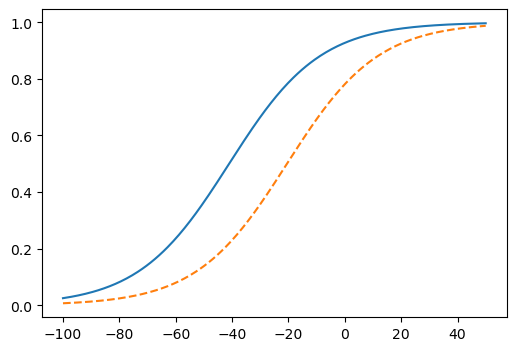

In [ ]:
def mgblock(v):
    mg = 1  # extracellular Mg2+ concentration in mM
    return 1 / (1 +  0.28 * np.exp(-0.062 * v) * (mg / 3.57))

def mgblock_hoc(v):
    return 1.0 / (1.0 + 0.28 * np.exp(-0.062 * v) )

v_vals = np.linspace(-100, 50, 300)
mg_vals = mgblock(v_vals)
plt.figure(figsize=(6,4))
plt.plot(v_vals, mg_vals, label='Python function', color='C0')
mg_vals_hoc = mgblock_hoc(v_vals)
plt.plot(v_vals, mg_vals_hoc, linestyle='--', label='HOC function', color='C1')



In [ ]:
np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])

IndexError: invalid index to scalar variable.

NameError: name 'create_comps_basal_clamp' is not defined

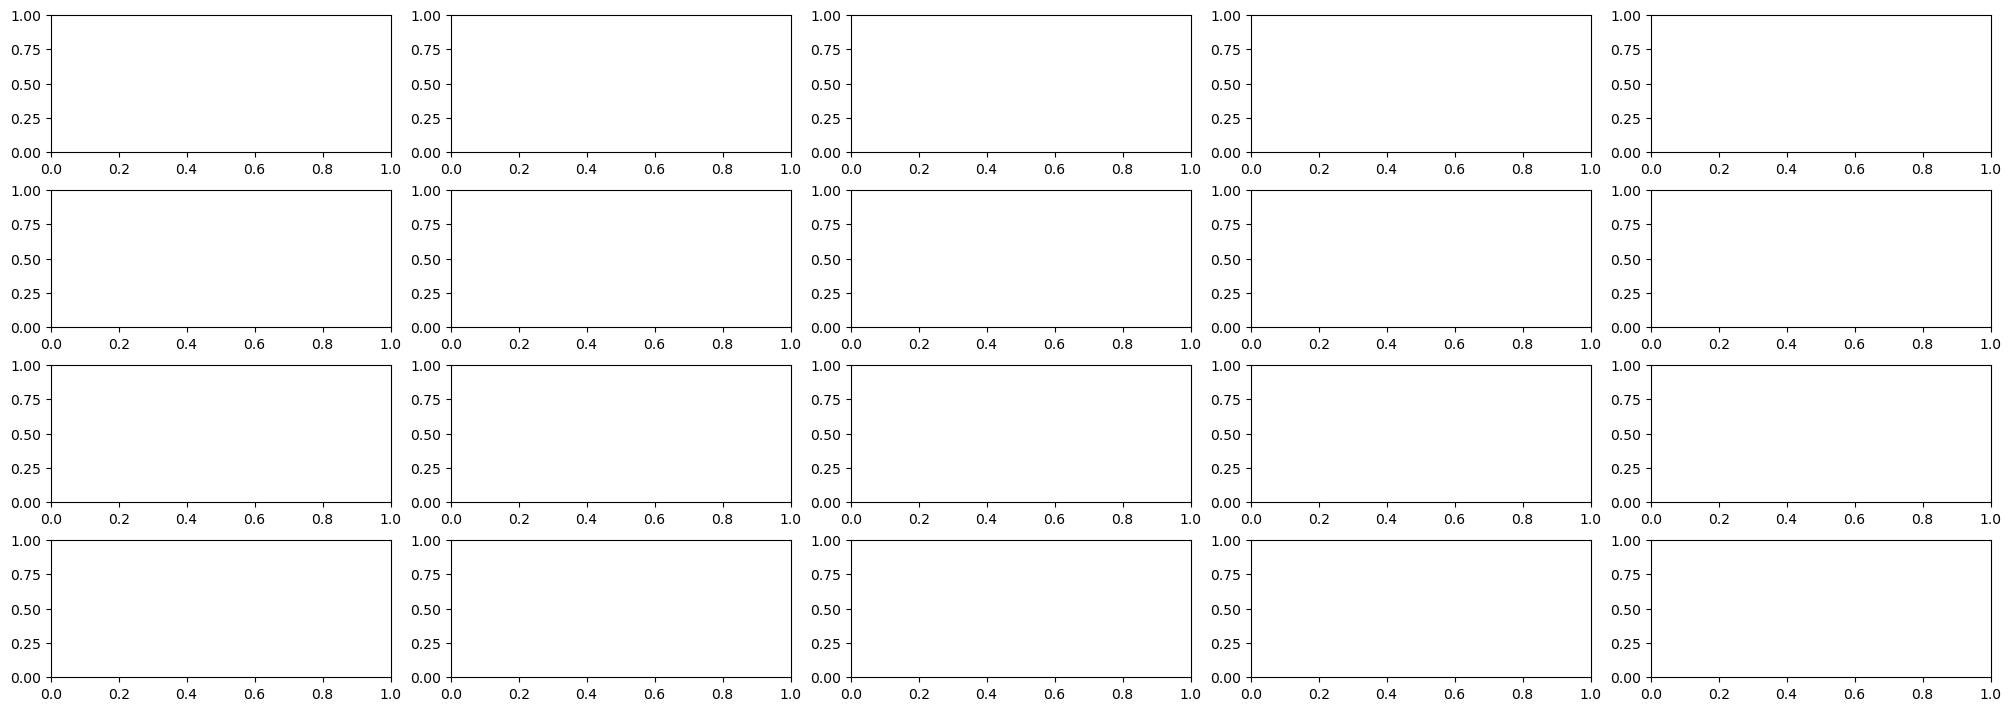

In [ ]:
fig, ax = plt.subplots(4, 5, figsize=(20, 7), constrained_layout=True)

bamps = np.linspace(2, 8, 10)
for b, bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.Exp2Syn(basal(0.5))
    syn.tau1 = 1
    syn.tau2 = 10
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,0].set_title('HNN NMDA (Exp2Syn)')

    ax[0,0].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    ax[0,0].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[0,0].set_ylabel('Membrane potential (mV)')
    ax[0,0].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    t1 = 10
    t2 = 21
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,0].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,0].set_xlabel('basal membrane pot. (mV)')
    ax[2,0].set_ylabel('PSP amplitude (mV)')
 
    ax[1,0].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[1,0].legend()
    ax[1,0].set_ylabel('NMDA synaptic current (nA)')
    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,0].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,0].set_xlabel('basal membrane pot. (mV)')
    ax[3,0].set_ylabel('NMDA current gradient (nA/ms)')
    # ax[1,0].text(150, -2, f'NMDA current grad: {nmda_grad:.4f} nA/ms', fontsize=12)

for b, bamp in enumerate(bamps):
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.Exp2Syn(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,1].set_title('HNN with adjusted taus')

    ax[0,1].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    ax[0,1].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[0,1].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,1].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,1].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,1].set_xlabel('basal membrane pot. (mV)')
    ax[2,1].set_ylabel('PSP amplitude (mV)')
 
    ax[1,1].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[1,1].legend()
    ax[1,1].set_ylabel('NMDA synaptic current (nA)')
    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,1].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,1].set_xlabel('basal membrane pot. (mV)')
    ax[3,1].set_ylabel('NMDA current gradient (nA/ms)')

for b, bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.NMDA(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,2].set_title('Netpyne NMDA')

    ax[0,2].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[0,2].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[0,2].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,2].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,2].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,2].set_xlabel('basal membrane pot. (mV)')
    ax[2,2].set_ylabel('PSP amplitude (mV)')
 
    ax[1,2].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[1,2].set_ylabel('NMDA synaptic current (nA)')

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,2].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,2].set_xlabel('basal membrane pot. (mV)')
    ax[3,2].set_ylabel('NMDA current gradient (nA/ms)')

for b,bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.NMDA(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    # nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    # nc.weight[0] = 0.05
    # nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_i)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,3].set_title('no NMDA')

    ax[0,3].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[0,3].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[0,3].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,3].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,3].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,3].set_xlabel('basal membrane pot. (mV)')
    ax[2,3].set_ylabel('PSP amplitude (mV)')
 
    ax[1,3].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[1,3].set_ylabel('NMDA synaptic current (nA)')

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,3].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,3].set_xlabel('basal membrane pot. (mV)')
    ax[3,3].set_ylabel('NMDA current gradient (nA/ms)')

for b,bamp in enumerate(bamps):
    h('forall delete_section()')
    del basal, soma #, syn, nc, stim, t, v_soma, v_basal, nmda_curr
    basal, soma, stim, stimb = create_comps_basal_clamp(bamp)
    syn = h.MyExp2SynNMDABB(basal(0.5))
    syn.tau1 = 15
    syn.tau2 = 150
    syn.e = 0

    nc = h.NetCon(soma(0.5)._ref_v, syn, sec=soma)
    nc.weight[0] = 0.2
    nc.delay = 1

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(soma(0.5)._ref_v)
    v_basal = h.Vector().record(basal(0.5)._ref_v)
    nmda_curr = h.Vector().record(syn._ref_iNMDA)
    h.finitialize(-65)
    h.continuerun(500)

    ax[0,4].set_title('NMDA + Ca2+')

    ax[0,4].plot(t, v_soma, color='tab:blue', alpha=1/(len(bamps)-b))
    
    ax[0,4].plot(t, v_basal, color='tab:orange', alpha=1/(len(bamps)-b))
    ax[0,4].plot(np.linspace(10,21, 100), np.ones(100,)*(-80), color='b', linestyle='--')
    ax[0,4].set_ylabel('Membrane potential (mV)')
    t1 = 10
    t2 = 19
    idx = np.where((t.as_numpy() >= t1) & (t.as_numpy() <= t2))[0]
    idx2 = np.where(t.as_numpy()>=25)
    psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
    print(psp)
    RMP = np.mean(v_basal.as_numpy()[idx[0]:idx[-1]])
    ax[2,4].plot(RMP, psp, 'o', color='tab:orange')
    ax[2,4].set_xlabel('basal membrane pot. (mV)')
    ax[2,4].set_ylabel('PSP amplitude (mV)')
 
    ax[1,4].plot(t, nmda_curr, color='C3', alpha=1/(len(bamps)-b))
    ax[1,4].set_ylabel('NMDA synaptic current (nA)')

    nmda_grad = np.max(np.gradient(nmda_curr.as_numpy()))
    ax[3,4].plot(RMP, nmda_grad, 'o', color='C3')
    ax[3,4].set_xlabel('basal membrane pot. (mV)')
    ax[3,4].set_ylabel('NMDA current gradient (nA/ms)')

fig.savefig(f'{pathfig}/NMDA_comparison_depolarization_long.png')

In [ ]:
psp = np.max(v_basal.as_numpy()[idx2[0][0]:]) - np.min(v_basal.as_numpy()[:t1])
psp

NameError: name 'v_basal' is not defined